# 2층 신경망 역전파 유도

입력 2개 → 은닉 2개 → 출력 1개인 신경망에서 **순전파 → 손실 → 역전파**를 수식으로 유도하고, 고정 예제를 손으로 계산한 뒤 NumPy 결과와 소수점 4자리까지 비교한다.

| 순서 | 내용 |
| --- | --- |
| 1 | 구조와 표기, 텐서 shape |
| 2 | 순전파 수식 |
| 3 | 역전파 수식 유도 (연쇄 법칙) |
| 4 | 고정 예제 손계산 (중간 체크포인트 + shape) |
| 5 | NumPy 검증: 손계산 · 해석적 역전파 · 수치 미분 |
| 6 | 기울기로 한 번 학습하면 손실이 줄어드는지 확인 |

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# notebooks/에서 열든 프로젝트 루트에서 열든 src를 import할 수 있게 한다.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
np.random.seed(42)
np.set_printoptions(precision=6, suppress=True)

## 1. 구조와 표기

```
x(2) ──W1(2×2), b1(2)──▶ z1(2) ──σ──▶ a1(2) ──W2(2), b2──▶ z2 ──σ──▶ ŷ ──BCE──▶ L
```

| 기호 | 의미 | shape |
| --- | --- | --- |
| $x$ | 입력 | (2,) |
| $W_1$ | 은닉층 가중치. $W_1[i,j]$ = 입력 $j$ → 은닉 $i$ | (2, 2) |
| $b_1$ | 은닉층 편향 | (2,) |
| $z_1, a_1$ | 은닉층 선형 결과, 활성화 결과 | (2,) |
| $W_2$ | 출력층 가중치 | (2,) |
| $b_2$ | 출력층 편향 | 스칼라 |
| $z_2, \hat y$ | 출력층 선형 결과, 예측 확률 | 스칼라 |
| $L$ | 손실 | 스칼라 |

**규칙:** 어떤 값에 대한 기울기 $\partial L/\partial(\cdot)$의 shape은 그 값의 shape과 같다. 가중치를 $W \leftarrow W - \eta\,\partial L/\partial W$로 갱신하려면 shape이 같아야 하기 때문이다. 역전파 중 shape이 맞지 않으면 유도가 틀렸다는 신호다.

## 2. 순전파 수식

$$
\begin{aligned}
z_1 &= W_1 x + b_1 && (2,) = (2,2)\,(2,) + (2,) \\
a_1 &= \sigma(z_1), \quad \sigma(z) = \frac{1}{1+e^{-z}} && (2,) \\
z_2 &= W_2 \cdot a_1 + b_2 && () = (2,)\cdot(2,) + () \\
\hat y &= \sigma(z_2) && () \\
L &= -\big[\,y \log \hat y + (1-y)\log(1-\hat y)\,\big] && ()
\end{aligned}
$$

원소별로 쓰면 $z_{1,i} = \sum_j W_1[i,j]\,x_j + b_{1,i}$이다.

## 3. 역전파 수식 유도

역전파는 손실 $L$에서 출발해 **그래프를 거꾸로** 따라가며 연쇄 법칙 $\dfrac{\partial L}{\partial u} = \dfrac{\partial L}{\partial v}\cdot\dfrac{\partial v}{\partial u}$를 반복한다. 각 단계는 "위에서 내려온 기울기 × 이 노드의 국소 미분"이다.

### 3-1. 출력 $\partial L/\partial \hat y$ — shape ()

$$
\frac{\partial L}{\partial \hat y} = -\frac{y}{\hat y} + \frac{1-y}{1-\hat y}
$$

### 3-2. 시그모이드 미분

$$
\sigma'(z) = \frac{e^{-z}}{(1+e^{-z})^2} = \sigma(z)\,\big(1-\sigma(z)\big)
$$

### 3-3. $\partial L/\partial z_2$ — shape () ← 체크포인트

$$
\frac{\partial L}{\partial z_2} = \frac{\partial L}{\partial \hat y}\,\hat y(1-\hat y)
= \Big(-\frac{y}{\hat y} + \frac{1-y}{1-\hat y}\Big)\hat y(1-\hat y)
= -y(1-\hat y) + (1-y)\hat y = \hat y - y
$$

Sigmoid와 BCE를 함께 쓰면 분모가 약분되어 **예측 − 정답**만 남는다. 출력층의 기울기가 오차 그 자체가 된다.

### 3-4. 출력층 파라미터

$z_2 = \sum_i W_{2,i}\,a_{1,i} + b_2$이므로 $\partial z_2/\partial W_{2,i} = a_{1,i}$, $\partial z_2/\partial b_2 = 1$.

$$
\frac{\partial L}{\partial W_2} = \frac{\partial L}{\partial z_2}\,a_1 \quad (2,), \qquad
\frac{\partial L}{\partial b_2} = \frac{\partial L}{\partial z_2} \quad ()
$$

### 3-5. 은닉층으로 전달 $\partial L/\partial a_1$ — shape (2,)

$\partial z_2/\partial a_{1,i} = W_{2,i}$이므로

$$
\frac{\partial L}{\partial a_1} = \frac{\partial L}{\partial z_2}\,W_2
$$

### 3-6. 은닉층 활성화 통과 $\partial L/\partial z_1$ — shape (2,) ← 체크포인트

$a_{1,i}$는 $z_{1,i}$에만 의존하므로 원소별 곱(⊙)이다.

$$
\frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial a_1} \odot \sigma'(z_1) = \frac{\partial L}{\partial a_1} \odot a_1 \odot (1-a_1)
$$

### 3-7. 은닉층 파라미터 $\partial L/\partial W_1$ — shape (2, 2)

$\partial z_{1,i}/\partial W_1[i,j] = x_j$이므로 $\dfrac{\partial L}{\partial W_1[i,j]} = \dfrac{\partial L}{\partial z_{1,i}}\,x_j$, 즉 외적이다.

$$
\frac{\partial L}{\partial W_1} = \frac{\partial L}{\partial z_1}\,x^{\top} = \mathrm{outer}\Big(\frac{\partial L}{\partial z_1},\,x\Big) \quad (2,1)(1,2) = (2,2), \qquad
\frac{\partial L}{\partial b_1} = \frac{\partial L}{\partial z_1}
$$

### 정리

| 단계 | 식 | shape |
| --- | --- | --- |
| $\partial L/\partial \hat y$ | $-y/\hat y + (1-y)/(1-\hat y)$ | () |
| $\partial L/\partial z_2$ | $\hat y - y$ | () |
| $\partial L/\partial W_2$ | $\partial L/\partial z_2 \cdot a_1$ | (2,) |
| $\partial L/\partial a_1$ | $\partial L/\partial z_2 \cdot W_2$ | (2,) |
| $\partial L/\partial z_1$ | $\partial L/\partial a_1 \odot a_1(1-a_1)$ | (2,) |
| $\partial L/\partial W_1$ | $\mathrm{outer}(\partial L/\partial z_1, x)$ | (2, 2) |

## 4. 고정 예제 손계산

| 값 | 설정 |
| --- | --- |
| $x$ | [1, 0] |
| $W_1$ | [[0.1, 0.2], [0.3, 0.4]] |
| $b_1$ | [0, 0] |
| $W_2$ | [0.5, 0.6] |
| $b_2$ | 0 |
| 활성화 / 손실 | Sigmoid / BCE |
| $y$ | 1 |

미션 설명의 정답 값이 비어 있어 결과 예시와 같은 $y=1$을 사용한다. 손으로 따라 할 수 있도록 곱셈·덧셈을 모두 적었다. $e^{-z}$ 값만 계산기를 사용하고, 각 줄의 결과는 소수점 6자리로 옮긴다.

### 4-1. 순전파

| 단계 | 계산 | 결과 | shape |
| --- | --- | --- | --- |
| $z_1$ | $[0.1\cdot1 + 0.2\cdot0 + 0,\ \ 0.3\cdot1 + 0.4\cdot0 + 0]$ | **[0.1, 0.3]** | (2,) |
| $e^{-z_1}$ | $[e^{-0.1},\ e^{-0.3}]$ | [0.904837, 0.740818] | (2,) |
| $a_1$ | $[1/1.904837,\ 1/1.740818]$ | **[0.524979, 0.574443]** | (2,) |
| $z_2$ | $0.5\cdot0.524979 + 0.6\cdot0.574443 + 0 = 0.262490 + 0.344666$ | **0.607156** | () |
| $e^{-z_2}$ | $e^{-0.607156}$ | 0.544898 | () |
| $\hat y$ | $1/1.544898$ | **0.647292** | () |
| $L$ | $-\log 0.647292$ | 0.434958 | () |

### 4-2. 역전파

| 단계 | 계산 | 결과 | shape |
| --- | --- | --- | --- |
| $\partial L/\partial \hat y$ | $-1/0.647292$ | **−1.544899** | () |
| $\partial L/\partial z_2$ ✔ | $0.647292 - 1$ (검산: $-1.544899 \times 0.647292 \times 0.352708 = -0.352708$) | **−0.352708** | () |
| $\partial L/\partial W_2$ | $-0.352708 \times [0.524979,\ 0.574443]$ | **[−0.185164, −0.202611]** | (2,) |
| $\partial L/\partial b_2$ | $= \partial L/\partial z_2$ | −0.352708 | () |
| $\partial L/\partial a_1$ | $-0.352708 \times [0.5,\ 0.6]$ | **[−0.176354, −0.211625]** | (2,) |
| $\sigma'(z_1)$ | $[0.524979 \times 0.475021,\ 0.574443 \times 0.425557]$ | [0.249376, 0.244458] | (2,) |
| $\partial L/\partial z_1$ ✔ | $[-0.176354 \times 0.249376,\ -0.211625 \times 0.244458]$ | **[−0.043979, −0.051733]** | (2,) |
| $\partial L/\partial W_1$ | $\begin{bmatrix}-0.043979\cdot1 & -0.043979\cdot0\\ -0.051733\cdot1 & -0.051733\cdot0\end{bmatrix}$ | **[[−0.043979, 0], [−0.051733, 0]]** | (2, 2) |
| $\partial L/\partial b_1$ | $= \partial L/\partial z_1$ | [−0.043979, −0.051733] | (2,) |

✔ 표시는 중간 체크포인트다. $\partial L/\partial z_2$가 맞으면 출력층이, $\partial L/\partial z_1$이 맞으면 은닉층까지의 연쇄가 맞다.

**관찰.** $x_2 = 0$이므로 $W_1$의 두 번째 열 기울기는 0이다. 이번 입력에서 쓰이지 않은 연결은 손실에 영향을 주지 않아 갱신되지 않는다.

**미션 예시와의 차이.** 미션 결과 예시는 $\partial L/\partial z_1 = [-0.0440, -0.0513]$이다. 그러나 $-0.2116 \times 0.2445 = -0.0517$이고, 아래 NumPy 계산과 수치 미분도 −0.0517이다. 예시의 −0.0513은 옮겨 적는 과정의 오류로 보인다.

In [2]:
# 손계산 결과를 소수점 4자리로 반올림해 적는다 (위 표의 굵은 값).
hand = {
    "z1": [0.1000, 0.3000],
    "a1": [0.5250, 0.5744],
    "z2": 0.6072,
    "y_pred": 0.6473,
    "dL_dy_pred": -1.5449,
    "dL_dz2": -0.3527,
    "dL_dW2": [-0.1852, -0.2026],
    "dL_da1": [-0.1764, -0.2116],
    "dL_dz1": [-0.0440, -0.0517],
    "dL_dW1": [[-0.0440, 0.0000], [-0.0517, 0.0000]],
}

## 5. NumPy 검증

### 5-1. 처음부터 NumPy로 직접 계산

모듈을 쓰지 않고 위 수식을 그대로 옮긴다.

In [3]:
x = np.array([1.0, 0.0])                     # (2,)
W1 = np.array([[0.1, 0.2], [0.3, 0.4]])      # (2, 2)
b1 = np.zeros(2)                             # (2,)
W2 = np.array([0.5, 0.6])                    # (2,)
b2 = 0.0                                     # ()
y = 1.0

sigmoid = lambda z: 1 / (1 + np.exp(-z))

# 순전파
z1 = W1 @ x + b1                             # (2,)
a1 = sigmoid(z1)                             # (2,)
z2 = W2 @ a1 + b2                            # ()
y_pred = sigmoid(z2)                         # ()
L = -(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))

# 역전파
dL_dy_pred = -y / y_pred + (1 - y) / (1 - y_pred)   # ()
dL_dz2 = dL_dy_pred * y_pred * (1 - y_pred)         # ()  = y_pred - y
dL_dW2 = dL_dz2 * a1                                # (2,)
dL_da1 = dL_dz2 * W2                                # (2,)
dL_dz1 = dL_da1 * a1 * (1 - a1)                     # (2,)
dL_dW1 = np.outer(dL_dz1, x)                        # (2, 2)

numpy_values = {"z1": z1, "a1": a1, "z2": z2, "y_pred": y_pred, "dL_dy_pred": dL_dy_pred,
                "dL_dz2": dL_dz2, "dL_dW2": dL_dW2, "dL_da1": dL_da1, "dL_dz1": dL_dz1, "dL_dW1": dL_dW1}
for name, value in numpy_values.items():
    print(f"{name:11s} shape={str(np.shape(value)):7s} {np.round(value, 6) + 0.0}")
print(f"loss = {L:.6f}")

z1          shape=(2,)    [0.1 0.3]
a1          shape=(2,)    [0.524979 0.574443]
z2          shape=()      0.607155
y_pred      shape=()      0.647292
dL_dy_pred  shape=()      -1.544899
dL_dz2      shape=()      -0.352708
dL_dW2      shape=(2,)    [-0.185165 -0.202611]
dL_da1      shape=(2,)    [-0.176354 -0.211625]
dL_dz1      shape=(2,)    [-0.043979 -0.051734]
dL_dW1      shape=(2, 2)  [[-0.043979  0.      ]
 [-0.051734  0.      ]]
loss = 0.434958


### 5-2. 손계산과 소수점 4자리 비교

In [4]:
all_match = True
for name, hand_value in hand.items():
    rounded = np.round(numpy_values[name], 4) + 0.0   # + 0.0: -0.0을 0.0으로 맞춘다
    match = np.array_equal(rounded, np.array(hand_value))
    all_match &= match
    print(f"{name:11s} 손계산={str(hand_value):32s} NumPy={str(rounded.tolist()):32s} {'일치' if match else '불일치'}")
assert all_match
print("\n손계산 결과와 NumPy 결과가 소수점 4자리까지 모두 일치한다.")

z1          손계산=[0.1, 0.3]                       NumPy=[0.1, 0.3]                       일치
a1          손계산=[0.525, 0.5744]                  NumPy=[0.525, 0.5744]                  일치
z2          손계산=0.6072                           NumPy=0.6072                           일치
y_pred      손계산=0.6473                           NumPy=0.6473                           일치
dL_dy_pred  손계산=-1.5449                          NumPy=-1.5449                          일치
dL_dz2      손계산=-0.3527                          NumPy=-0.3527                          일치
dL_dW2      손계산=[-0.1852, -0.2026]               NumPy=[-0.1852, -0.2026]               일치
dL_da1      손계산=[-0.1764, -0.2116]               NumPy=[-0.1764, -0.2116]               일치
dL_dz1      손계산=[-0.044, -0.0517]                NumPy=[-0.044, -0.0517]                일치
dL_dW1      손계산=[[-0.044, 0.0], [-0.0517, 0.0]]  NumPy=[[-0.044, 0.0], [-0.0517, 0.0]]  일치

손계산 결과와 NumPy 결과가 소수점 4자리까지 모두 일치한다.


### 5-3. 모듈 구현(`src/neural_net.py`)과 수치 미분으로 교차 검증

해석적으로 유도한 기울기가 맞다면, 가중치를 아주 조금 움직였을 때 손실 변화량(중심차분)과 같아야 한다. 이 검증은 유도 과정과 무관한 독립적인 확인이다.

In [5]:
from src.neural_net import example_network
from src.calculus import numerical_gradient

net, x_ex, y_ex = example_network()
cache = net.forward(x_ex, y_ex)
grads = net.backward(cache, y_ex)

num_W1 = numerical_gradient(lambda W: net.loss_with(x_ex, y_ex, W1=W), net.W1)
num_W2 = numerical_gradient(lambda W: net.loss_with(x_ex, y_ex, W2=W), net.W2)
num_b1 = numerical_gradient(lambda b: net.loss_with(x_ex, y_ex, b1=b), net.b1)
num_b2 = numerical_gradient(lambda b: net.loss_with(x_ex, y_ex, b2=float(b)), np.array(net.b2))

print("dL/dW1 역전파\n", grads["dL_dW1"] + 0.0, "\n수치 미분\n", num_W1 + 0.0)
print("dL/dW2 역전파", grads["dL_dW2"], " 수치 미분", num_W2)
print("dL/db1 역전파", grads["dL_db1"], " 수치 미분", num_b1)
print("dL/db2 역전파", grads["dL_db2"], " 수치 미분", float(num_b2))
max_diff = max(np.abs(num_W1 - grads["dL_dW1"]).max(), np.abs(num_W2 - grads["dL_dW2"]).max(),
               np.abs(num_b1 - grads["dL_db1"]).max(), abs(float(num_b2) - grads["dL_db2"]))
print(f"\n최대 차이 = {max_diff:.2e}")
assert max_diff < 1e-8
assert np.allclose(grads["dL_dW1"], dL_dW1) and np.isclose(grads["dL_dz2"], dL_dz2)

dL/dW1 역전파
 [[-0.043979  0.      ]
 [-0.051734  0.      ]] 
수치 미분
 [[-0.043979  0.      ]
 [-0.051734  0.      ]]
dL/dW2 역전파 [-0.185165 -0.202611]  수치 미분 [-0.185165 -0.202611]
dL/db1 역전파 [-0.043979 -0.051734]  수치 미분 [-0.043979 -0.051734]
dL/db2 역전파 -0.35270843000538216  수치 미분 -0.3527084300125604

최대 차이 = 1.06e-11


## 6. 기울기로 한 번 학습하기

$\theta \leftarrow \theta - \eta\,\partial L/\partial \theta$로 한 번 갱신하면 손실이 줄어야 한다. 정답이 1인데 예측이 0.647이므로, 출력이 커지는 방향으로 가중치가 움직인다.

1회 갱신 후 손실: 0.434958 → 0.339529
갱신된 W2: [1.2239 1.3914]  갱신된 W1:
 [[0.351  0.2   ]
 [0.5764 0.4   ]]


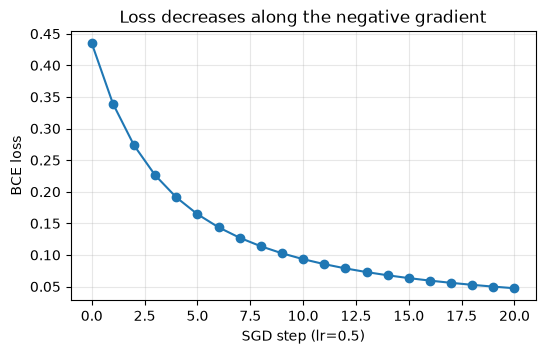

In [6]:
eta = 0.5
losses = [cache["loss"]]
for step in range(20):
    c = net.forward(x_ex, y_ex)
    net.sgd_step(net.backward(c, y_ex), eta)
    losses.append(net.forward(x_ex, y_ex)["loss"])
print(f"1회 갱신 후 손실: {losses[0]:.6f} → {losses[1]:.6f}")
print("갱신된 W2:", np.round(net.W2, 4), " 갱신된 W1:\n", np.round(net.W1, 4))

plt.figure(figsize=(6, 3.5))
plt.plot(losses, "o-")
plt.xlabel("SGD step (lr=0.5)")
plt.ylabel("BCE loss")
plt.title("Loss decreases along the negative gradient")
plt.grid(alpha=0.3)
plt.show()

## 정리

- 역전파는 **위에서 내려온 기울기 × 국소 미분**을 출력에서 입력 방향으로 반복하는 것이다.
- Sigmoid + BCE 조합은 $\partial L/\partial z_2 = \hat y - y$로 깔끔해진다.
- 각 기울기의 shape은 대응하는 값의 shape과 같고, 가중치 기울기는 "뒤에서 온 오차 ⊗ 앞에서 온 입력"인 외적 꼴이다.
- 손계산 · NumPy · 수치 미분, 세 가지 독립적인 계산이 같은 값을 냈다.